# Noise simulation

ObjectNat has three noise models with the same inputs (source level `source_noise_db` in dB at 1 m and
characteristic frequency `geometric_mean_freq_hz` in Hz, per source or as arguments):

1. `simulate_noise_grid`: levels on a receiver grid, direct paths and first-order reflections, energy summation;
   point, line and polygon sources;
2. `simulate_noise`: wave-front model for point sources with multiple reflections and vegetation;
3. `calculate_simplified_noise_frame`: visibility masks and distance decay, for a quick estimate.

The sources here are a street (a line through the open space between blocks) and two point sources.

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from matplotlib import colors as mcolors

from objectnat import calculate_simplified_noise_frame, config, simulate_noise, simulate_noise_grid

config.set_enable_tqdm(False)

obstacles = gpd.read_parquet("examples_data/buildings.parquet")  # EPSG:32636, metres
trees = gpd.read_parquet("examples_data/trees.parquet")

In [3]:
import matplotlib.pyplot as plt
import numpy as np


def map_axes(ax, bounds, step=100):
    """Show `bounds` (x0, y0, x1, y1 in metres) with axes in metres from the lower-left corner."""
    x0, y0, x1, y1 = bounds
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal")
    ax.set_xticks(x0 + np.arange(0, x1 - x0 + 1, step), [f"{v:g}" for v in np.arange(0, x1 - x0 + 1, step)])
    ax.set_yticks(y0 + np.arange(0, y1 - y0 + 1, step), [f"{v:g}" for v in np.arange(0, y1 - y0 + 1, step)])
    ax.set_xlabel("x, m")
    ax.set_ylabel("y, m")
    ax.tick_params(labelsize=8)

In [4]:
centre = (346050, 6647450)
square = shapely.box(centre[0] - 300, centre[1] - 300, centre[0] + 300, centre[1] + 300)
scene = obstacles[obstacles.intersects(square.buffer(200))]
vegetation = trees[trees.intersects(square)]

street = shapely.LineString([(345805, 6647230), (345805, 6647650)])  # street between two blocks
points = gpd.GeoDataFrame(
    {"source_noise_db": [95.0, 85.0], "geometric_mean_freq_hz": [2000.0, 500.0]},
    geometry=[shapely.Point(346145, 6647505), shapely.Point(346240, 6647260)],
    crs=obstacles.crs,
)
road = gpd.GeoDataFrame({"source_noise_db": [80.0], "geometric_mean_freq_hz": [1000.0]}, geometry=[street], crs=obstacles.crs)
sources = pd.concat([road, points], ignore_index=True)
print("street crosses a building:", scene.intersects(street).any(),
      "| point inside a building:", scene.contains(points.union_all()).any())
sources

street crosses a building: False | point inside a building: False


,source_noise_db,geometric_mean_freq_hz,geometry
0,80.0,1000.0,"LINESTRING (345805 6647230, 345805 6647650)"
1,95.0,2000.0,POINT (346145 6647505)
2,85.0,500.0,POINT (346240 6647260)


In [5]:
def show_levels(ax, bands, title, lo=40, hi=95):
    cmap = plt.get_cmap("magma_r", int((hi - lo) / 5))
    norm = mcolors.Normalize(lo, hi)
    bands.plot(ax=ax, column="noise_level", cmap=cmap, norm=norm, linewidth=0)
    vegetation.clip(square).plot(ax=ax, facecolor="none", edgecolor="#2ca25f", hatch="///", linewidth=0.5)
    scene.clip(square).plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    sources.plot(ax=ax, color="#2b7bba", linewidth=1.5, markersize=25)
    map_axes(ax, square.bounds)
    ax.set_title(title)
    return plt.cm.ScalarMappable(norm=norm, cmap=cmap)

## 1. Receiver grid

Receivers every `grid_step` metres; the street is sampled every `source_spacing` metres (default 5) so that it
follows the line-source law. Levels are grouped into bands of `db_sim_step` dB (`noise_level` is the upper bound of
the band); `return_receivers=True` also returns the exact level of every receiver.

In [6]:
import time

start = time.perf_counter()
grid_bands, receivers = simulate_noise_grid(
    sources, scene, trees=vegetation, grid_step=2, db_sim_step=5, target_noise_db=40,
    reflections=True, reflection_max_dist=50, return_receivers=True,
)
print(f"{len(receivers)} receivers above 40 dB in {time.perf_counter() - start:.1f} s")
receivers["noise_level"].describe().round(1)

42005 receivers above 40 dB in 12.7 s


count    42005.0
mean        52.3
std          9.3
min         40.0
25%         45.1
50%         50.0
75%         57.5
max         92.1
Name: noise_level, dtype: float64

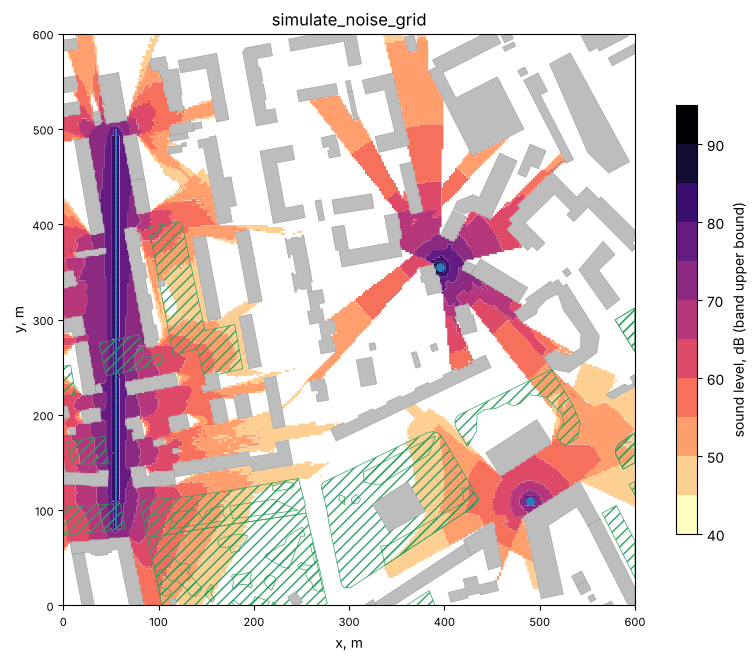

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 6.5), constrained_layout=True)
sm = show_levels(ax, grid_bands, "simulate_noise_grid")
fig.colorbar(sm, ax=ax, shrink=0.75, label="sound level, dB (band upper bound)")
plt.show()

Two equal sources add +3 dB in this model, because energies are summed. Without reflections the area behind the
buildings stays silent:

In [8]:
direct_only = simulate_noise_grid(sources, scene, trees=vegetation, grid_step=2, db_sim_step=5, reflections=False)
area = pd.DataFrame({
    "with reflections, ha": grid_bands.set_index("noise_level").area / 1e4,
    "direct only, ha": direct_only.set_index("noise_level").area / 1e4,
}).fillna(0)
area.round(2)

,"with reflections, ha","direct only, ha"
noise_level,,
45.0,4.12,3.87
50.0,4.20,3.71
55.0,3.12,2.57
60.0,1.94,1.57
65.0,1.18,1.01
70.0,1.07,0.92
75.0,0.70,0.55
80.0,0.26,0.22
85.0,0.08,0.08


## 2. Wave-front simulation

`simulate_noise` takes point sources only. It propagates the sound in layers of `db_sim_step` dB with up to
`reflection_n` reflections and vegetation attenuation.

In [9]:
start = time.perf_counter()
wave = simulate_noise(
    source_points=points,
    obstacles=scene,
    standart_absorb_ratio=0.05,
    trees=vegetation,
    tree_resolution=4,
    air_temperature=20,
    target_noise_db=40,
    db_sim_step=5,
    reflection_n=2,
    dead_area_r=5,
    use_parallel=False,
)
print(f"{time.perf_counter() - start:.1f} s, {len(wave)} level bands")

10.2 s, 72 level bands


## 3. Simplified noise frame

`calculate_simplified_noise_frame` accepts point, line and polygon sources and needs no propagation simulation;
obstacles act only as line-of-sight masks.

0.4 s


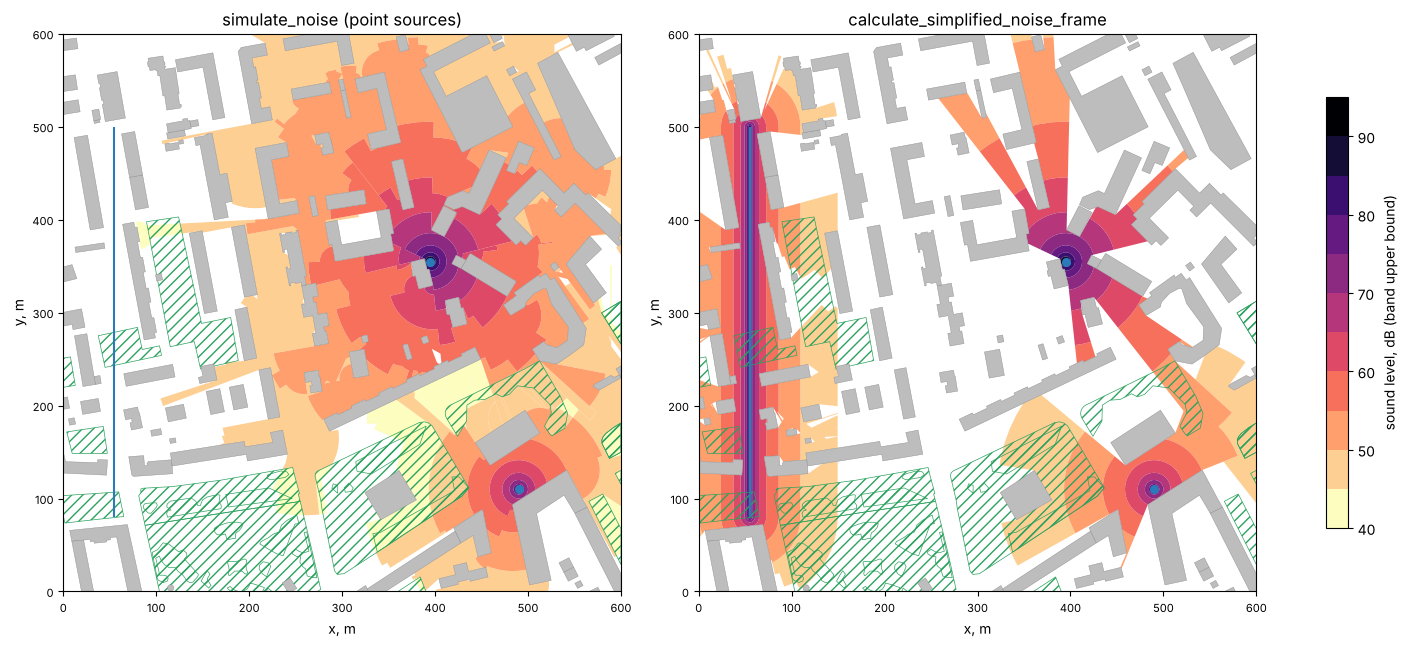

In [10]:
start = time.perf_counter()
frame = calculate_simplified_noise_frame(sources, scene, air_temperature=20, target_noise_db=40, db_sim_step=5)
print(f"{time.perf_counter() - start:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), constrained_layout=True)
show_levels(axs[0], wave, "simulate_noise (point sources)")
sm = show_levels(axs[1], frame, "calculate_simplified_noise_frame")
fig.colorbar(sm, ax=axs, shrink=0.75, label="sound level, dB (band upper bound)")
plt.show()

The models differ: `simulate_noise_grid` and `simulate_noise` include reflections, the simplified frame does not;
`simulate_noise` and the simplified frame combine sources by the band maximum, `simulate_noise_grid` by energy
summation. None of them models ground effect or diffraction. See the [noise page](../noise.rst).